In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.dpi"] = 140
sns.set_theme(style="whitegrid", palette="Set2")

BASE_DIR = Path(r"C:\Projet Niger Labor Market\niger_jobs_scraper\data\cleaned")
emp = pd.read_csv(BASE_DIR / "offres_niger_nlp.csv")


In [2]:
# ==============================================================================
# 1. INGENIERIE DES INDICATEURS COMPOSITES (ODD 8 & ADEQUATION EFTP)
# ==============================================================================
def split_items(val):
    if pd.isna(val) or str(val).strip() == "Non détecté":
        return []
    return [x.strip() for x in str(val).split(";") if x.strip()]

for col in ["savoirs", "savoir_faire", "outils", "savoir_etre"]:
    emp[col + "_list"] = emp[col + "_str"].apply(split_items)
    emp["nb_" + col] = emp[col + "_list"].apply(len)

emp["densite_competences"] = (
    emp["nb_savoirs"] + emp["nb_savoir_faire"] + emp["nb_outils"] + emp["nb_savoir_etre"]
)

# 1A. Sous-scores normalisés [0, 1] pour l'Indice de Travail Décent (ODD 8)
map_contrat_odd8 = {
    "CDI": 1.00,
    "CDD": 0.70,
    "Prestation / Consultance": 0.45,
    "Stage": 0.30,
    "Bénévolat / Volontariat": 0.10,
    "Non précisé / Autre": 0.25,
}
map_sal_odd8 = {
    "1. Montant explicite affiché": 1.00,
    "2. Grille / Grade / Avantages mentionnés": 0.65,
    "3. Opacité salariale totale": 0.15,
}

emp["s_stabilite_contrat"] = emp["contrat_canonique"].map(map_contrat_odd8).fillna(0.25)
emp["s_transparence_sal"] = emp["transparence_salariale"].map(map_sal_odd8).fillna(0.15)
emp["s_clarte_localisation"] = np.where(emp["region"].notna() & (emp["region"] != "Non précisé"), 1.0, 0.3)

# Indice ODD 8 [0 - 100] : Stabilité contractuelle (45%), Transparence salariale (40%), Clarté géographique (15%)
emp["indice_travail_decent_odd8"] = (
    0.45 * emp["s_stabilite_contrat"]
    + 0.40 * emp["s_transparence_sal"]
    + 0.15 * emp["s_clarte_localisation"]
) * 100

# 1B. Indice d'Accessibilité Primo-Demandeurs / Jeunes Diplômés EFTP [0 - 100]
niv_med = emp["niveau_etude_rang"].fillna(emp["niveau_etude_rang"].median())
exp_med = emp["exp_min"].fillna(emp["exp_min"].median())

s_diplome_ouvert = 1.0 - ((niv_med - 1.0) / 4.0).clip(0, 1)  # 1 si Bac/BEPC, 0 si Doctorat
s_exp_ouverte = 1.0 - (exp_med / 10.0).clip(0, 1)             # 1 si 0 an, 0 si >= 10 ans
s_contrat_entree = np.where(
    emp["contrat_canonique"].isin(["Stage", "Bénévolat / Volontariat"])
    | emp["isco08_groupe"].str.startswith(("3.", "4.", "5.", "7.", "8.", "9.")),
    1.0,
    0.3,
)

emp["indice_accessibilite_jeunes"] = (
    0.45 * s_exp_ouverte
    + 0.35 * s_diplome_ouvert
    + 0.20 * s_contrat_entree
) * 100

# 1C. Indice de Tension & Sélectivité du Poste [0 - 100]
scaler_01 = MinMaxScaler()
mat_tension = scaler_01.fit_transform(
    pd.DataFrame({
        "duree": emp["duree_affichage_j"].fillna(emp["duree_affichage_j"].median()),
        "exp": exp_med,
        "comp": emp["densite_competences"],
    })
)
emp["indice_tension_selectivite"] = (
    0.40 * mat_tension[:, 0] + 0.35 * mat_tension[:, 1] + 0.25 * mat_tension[:, 2]
) * 100

print("=== 1. SYNTHESE DES INDICES COMPOSITES ODD 8 & EFTP (n=70) ===")
print(
    emp[["indice_travail_decent_odd8", "indice_accessibilite_jeunes", "indice_tension_selectivite"]]
    .describe()
    .round(2)
)

print("\nComparaison des indices par Type d'employeur :")
print(
    emp.groupby("type_employeur")[
        ["indice_travail_decent_odd8", "indice_accessibilite_jeunes", "indice_tension_selectivite"]
    ]
    .agg(["count", "mean", "median"])
    .round(1)
)


=== 1. SYNTHESE DES INDICES COMPOSITES ODD 8 & EFTP (n=70) ===
       indice_travail_decent_odd8  indice_accessibilite_jeunes  \
count                       70.00                        70.00   
mean                        53.22                        55.51   
std                         11.84                        17.46   
min                         25.50                        19.12   
25%                         52.50                        43.19   
50%                         52.50                        55.00   
75%                         52.50                        68.94   
max                         72.50                        91.00   

       indice_tension_selectivite  
count                       70.00  
mean                        35.95  
std                         13.07  
min                          5.97  
25%                         28.26  
50%                         35.23  
75%                         41.94  
max                         71.88  

Comparaison des i

In [3]:
# ==============================================================================
# 2. SEGMENTATION NON SUPERVISEE DES PROFILS METIERS (ACP + K-MEANS)
# ==============================================================================
emp["est_ong_onu"] = (emp["bloc_employeur"] == "ONG, ONU & Projets").astype(int)
emp["est_cdi"] = (emp["contrat_canonique"] == "CDI").astype(int)
emp["a_transparence_sal"] = (emp["transparence_salariale"] != "3. Opacité salariale totale").astype(int)

features_clust = [
    "niveau_etude_rang",
    "exp_min",
    "duree_affichage_j",
    "nb_savoirs",
    "nb_savoir_faire",
    "nb_outils",
    "nb_savoir_etre",
    "est_ong_onu",
    "est_cdi",
    "a_transparence_sal",
]

imputer = SimpleImputer(strategy="median")
X_imp = imputer.fit_transform(emp[features_clust])
scaler_std = StandardScaler()
X_scaled = scaler_std.fit_transform(X_imp)

# Recherche du nombre optimal de clusters k via le score de Silhouette
sil_scores = {}
for k in range(2, 6):
    km_tmp = KMeans(n_clusters=k, random_state=42, n_init=25)
    labels_tmp = km_tmp.fit_predict(X_scaled)
    sil_scores[k] = silhouette_score(X_scaled, labels_tmp)

print("\n=== 2. SELECTION DU NOMBRE DE CLUSTERS (SCORE DE SILHOUETTE) ===")
for k, sc in sil_scores.items():
    print(f"  k = {k} clusters -> Silhouette = {sc:.3f}")

k_opt = max(sil_scores, key=sil_scores.get)
km_final = KMeans(n_clusters=k_opt, random_state=42, n_init=30)
emp["cluster_id"] = km_final.fit_predict(X_scaled)

# Projection ACP (2 axes principaux)
pca = PCA(n_components=2, random_state=42)
coords_pca = pca.fit_transform(X_scaled)
emp["pca_1"] = coords_pca[:, 0]
emp["pca_2"] = coords_pca[:, 1]
var_exp = pca.explained_variance_ratio_ * 100

print(f"\nVariance expliquée par l'ACP : Axe 1 = {var_exp[0]:.1f}%, Axe 2 = {var_exp[1]:.1f}% (Cumul = {var_exp.sum():.1f}%)")
print("\nProfil moyen des clusters identifiés :")
profil_clusters = emp.groupby("cluster_id").agg(
    effectif=("id_offre", "count"),
    diplome_rang_moy=("niveau_etude_rang", "mean"),
    exp_min_moy=("exp_min", "mean"),
    duree_j_moy=("duree_affichage_j", "mean"),
    densite_comp_moy=("densite_competences", "mean"),
    part_ong_onu_pct=("est_ong_onu", lambda s: s.mean() * 100),
    part_cdi_pct=("est_cdi", lambda s: s.mean() * 100),
    odd8_moy=("indice_travail_decent_odd8", "mean"),
    access_jeunes_moy=("indice_accessibilite_jeunes", "mean"),
).round(1)
print(profil_clusters)




=== 2. SELECTION DU NOMBRE DE CLUSTERS (SCORE DE SILHOUETTE) ===
  k = 2 clusters -> Silhouette = 0.194
  k = 3 clusters -> Silhouette = 0.215
  k = 4 clusters -> Silhouette = 0.173
  k = 5 clusters -> Silhouette = 0.191

Variance expliquée par l'ACP : Axe 1 = 28.1%, Axe 2 = 18.9% (Cumul = 47.0%)

Profil moyen des clusters identifiés :
            effectif  diplome_rang_moy  exp_min_moy  duree_j_moy  \
cluster_id                                                         
0                  2               3.8          7.5         24.0   
1                 35               3.3          4.1         10.1   
2                 33               2.7          3.9         14.7   

            densite_comp_moy  part_ong_onu_pct  part_cdi_pct  odd8_moy  \
cluster_id                                                               
0                       11.0             100.0         100.0      66.0   
1                       14.3              91.4           0.0      57.9   
2                       

In [4]:
# ==============================================================================
# 3. ANALYSE ECONOMETRIQUE : DETERMINANTS DE LA TENSION (DUREE D'AFFICHAGE)
# ==============================================================================
df_reg = emp[["duree_affichage_j", "exp_min", "niveau_etude_rang", "densite_competences", "est_ong_onu"]].dropna().copy()
y = df_reg["duree_affichage_j"].values
X_mat = np.column_stack([
    np.ones(len(df_reg)),
    df_reg["exp_min"].values,
    df_reg["niveau_etude_rang"].values,
    df_reg["densite_competences"].values,
    df_reg["est_ong_onu"].values,
])
col_names = ["Constante", "Expérience min (années)", "Niveau diplôme (rang)", "Densité compétences", "Employeur ONG/ONU (0/1)"]

# Estimation MCO (OLS) & Erreurs-types robustes de White (HC3)
beta = np.linalg.lstsq(X_mat, y, rcond=None)[0]
y_hat = X_mat @ beta
resid = y - y_hat
n_obs, k_params = X_mat.shape
r2 = 1.0 - (np.sum(resid**2) / np.sum((y - y.mean())**2))
r2_adj = 1.0 - (1.0 - r2) * (n_obs - 1) / (n_obs - k_params)

XtX_inv = np.linalg.inv(X_mat.T @ X_mat)
hat_diag = np.sum((X_mat @ XtX_inv) * X_mat, axis=1)
u_hc3 = resid / (1.0 - hat_diag)
cov_hc3 = XtX_inv @ (X_mat.T @ np.diag(u_hc3**2) @ X_mat) @ XtX_inv
se_hc3 = np.sqrt(np.diag(cov_hc3))
t_stats = beta / se_hc3
p_vals = 2 * (1 - stats.t.cdf(np.abs(t_stats), df=n_obs - k_params))

res_ols = pd.DataFrame({
    "Variable": col_names,
    "Coef_Beta": beta.round(3),
    "Erreur_Std_HC3": se_hc3.round(3),
    "t_stat": t_stats.round(2),
    "p_value": p_vals.round(4),
})
print(f"\n=== 3. REGRESSION MCO ROBUSTE (HC3) SUR LA DUREE D'AFFICHAGE (n={n_obs}, R²={r2:.3f}, R²_ajusté={r2_adj:.3f}) ===")
print(res_ols.to_string(index=False))



=== 3. REGRESSION MCO ROBUSTE (HC3) SUR LA DUREE D'AFFICHAGE (n=56, R²=0.343, R²_ajusté=0.291) ===
               Variable  Coef_Beta  Erreur_Std_HC3  t_stat  p_value
              Constante      9.159           3.593    2.55   0.0138
Expérience min (années)      1.259           0.610    2.06   0.0441
  Niveau diplôme (rang)      1.490           0.883    1.69   0.0978
    Densité compétences     -0.421           0.201   -2.10   0.0410
Employeur ONG/ONU (0/1)     -3.290           1.902   -1.73   0.0898


In [5]:
# ==============================================================================
# 4. MATRICE DECISIONNELLE EFTP : CURRICULA & COMPETENCES PAR MACRO-SECTEUR
# ==============================================================================
def top_n_items(series_of_lists, n=3):
    exploded = series_of_lists.explode().dropna()
    if exploded.empty:
        return "Non spécifié"
    vc = exploded.value_counts().head(n)
    return " | ".join([f"{k} ({v})" for k, v in vc.items()])

matrice_eftp = emp.groupby("secteur_canonique").agg(
    nb_offres=("id_offre", "count"),
    diplome_median=("niveau_etude_std", lambda s: s.mode().iloc[0] if not s.mode().empty else "Non précisé"),
    exp_min_mediane=("exp_min", "median"),
    access_jeunes_moy=("indice_accessibilite_jeunes", "mean"),
    odd8_moy=("indice_travail_decent_odd8", "mean"),
    top_savoirs=("savoirs_list", lambda s: top_n_items(s, 3)),
    top_savoir_faire=("savoir_faire_list", lambda s: top_n_items(s, 3)),
    top_outils=("outils_list", lambda s: top_n_items(s, 2)),
).sort_values("nb_offres", ascending=False).round(1)

print("\n=== 4. MATRICE D'ALIGNEMENT EFTP PAR MACRO-SECTEUR ===")
print(matrice_eftp[["nb_offres", "diplome_median", "exp_min_mediane", "access_jeunes_moy", "odd8_moy"]])

# Répartition géographique (Niamey vs Régions intérieures)
emp["zone_geo"] = np.where(
    emp["region"].fillna("").str.contains("niamey", case=False),
    "Niamey (Capitale)",
    np.where(emp["est_offre_nationale"], "National / Multi-régions", "Régions intérieures (Diffa, Tillabéri, Maradi, Zinder...)")
)
matrice_geo = emp.groupby("zone_geo").agg(
    nb_offres=("id_offre", "count"),
    part_pct=("id_offre", lambda s: len(s) / len(emp) * 100),
    exp_med=("exp_min", "median"),
    odd8_moy=("indice_travail_decent_odd8", "mean"),
    access_jeunes_moy=("indice_accessibilite_jeunes", "mean"),
).round(1)
print("\n=== 5. REPARTITION SPATIALE DES OPPORTUNITES ===")
print(matrice_geo)


=== 4. MATRICE D'ALIGNEMENT EFTP PAR MACRO-SECTEUR ===
                                          nb_offres     diplome_median  \
secteur_canonique                                                        
Finance, Banque & Comptabilité                   12  Bac+2 / BTS / DUT   
Humanitaire, Projets & Social                    11    Bac+3 / Licence   
Santé & Action médicale                          11    Bac+3 / Licence   
Eau, Hygiène & Assainissement (WASH)              8    Bac+3 / Licence   
Administration, Conseil & Services                6     Bac+5 / Master   
BTP, Industrie, Mines & Énergie                   6  Bac+2 / BTS / DUT   
Commerce, Marketing & Services marchands          5  Bac+2 / BTS / DUT   
Agriculture, Élevage & Environnement              3    Bac+3 / Licence   
Informatique, Télécoms & Digital                  3        Non précisé   
Éducation, Formation & Recherche                  3     Bac+5 / Master   
Logistique, Transport & Supply Chain              2     

C:\Users\AbdoulLocal\AppData\Local\Temp\ipykernel_23148\3743595608.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=emp, x="type_employeur", y="indice_travail_decent_odd8", order=order_emp, ax=ax4, palette="Set2", width=0.45)
C:\Users\AbdoulLocal\AppData\Local\Temp\ipykernel_23148\3743595608.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax4.set_xticklabels(labels_emp, fontsize=9)


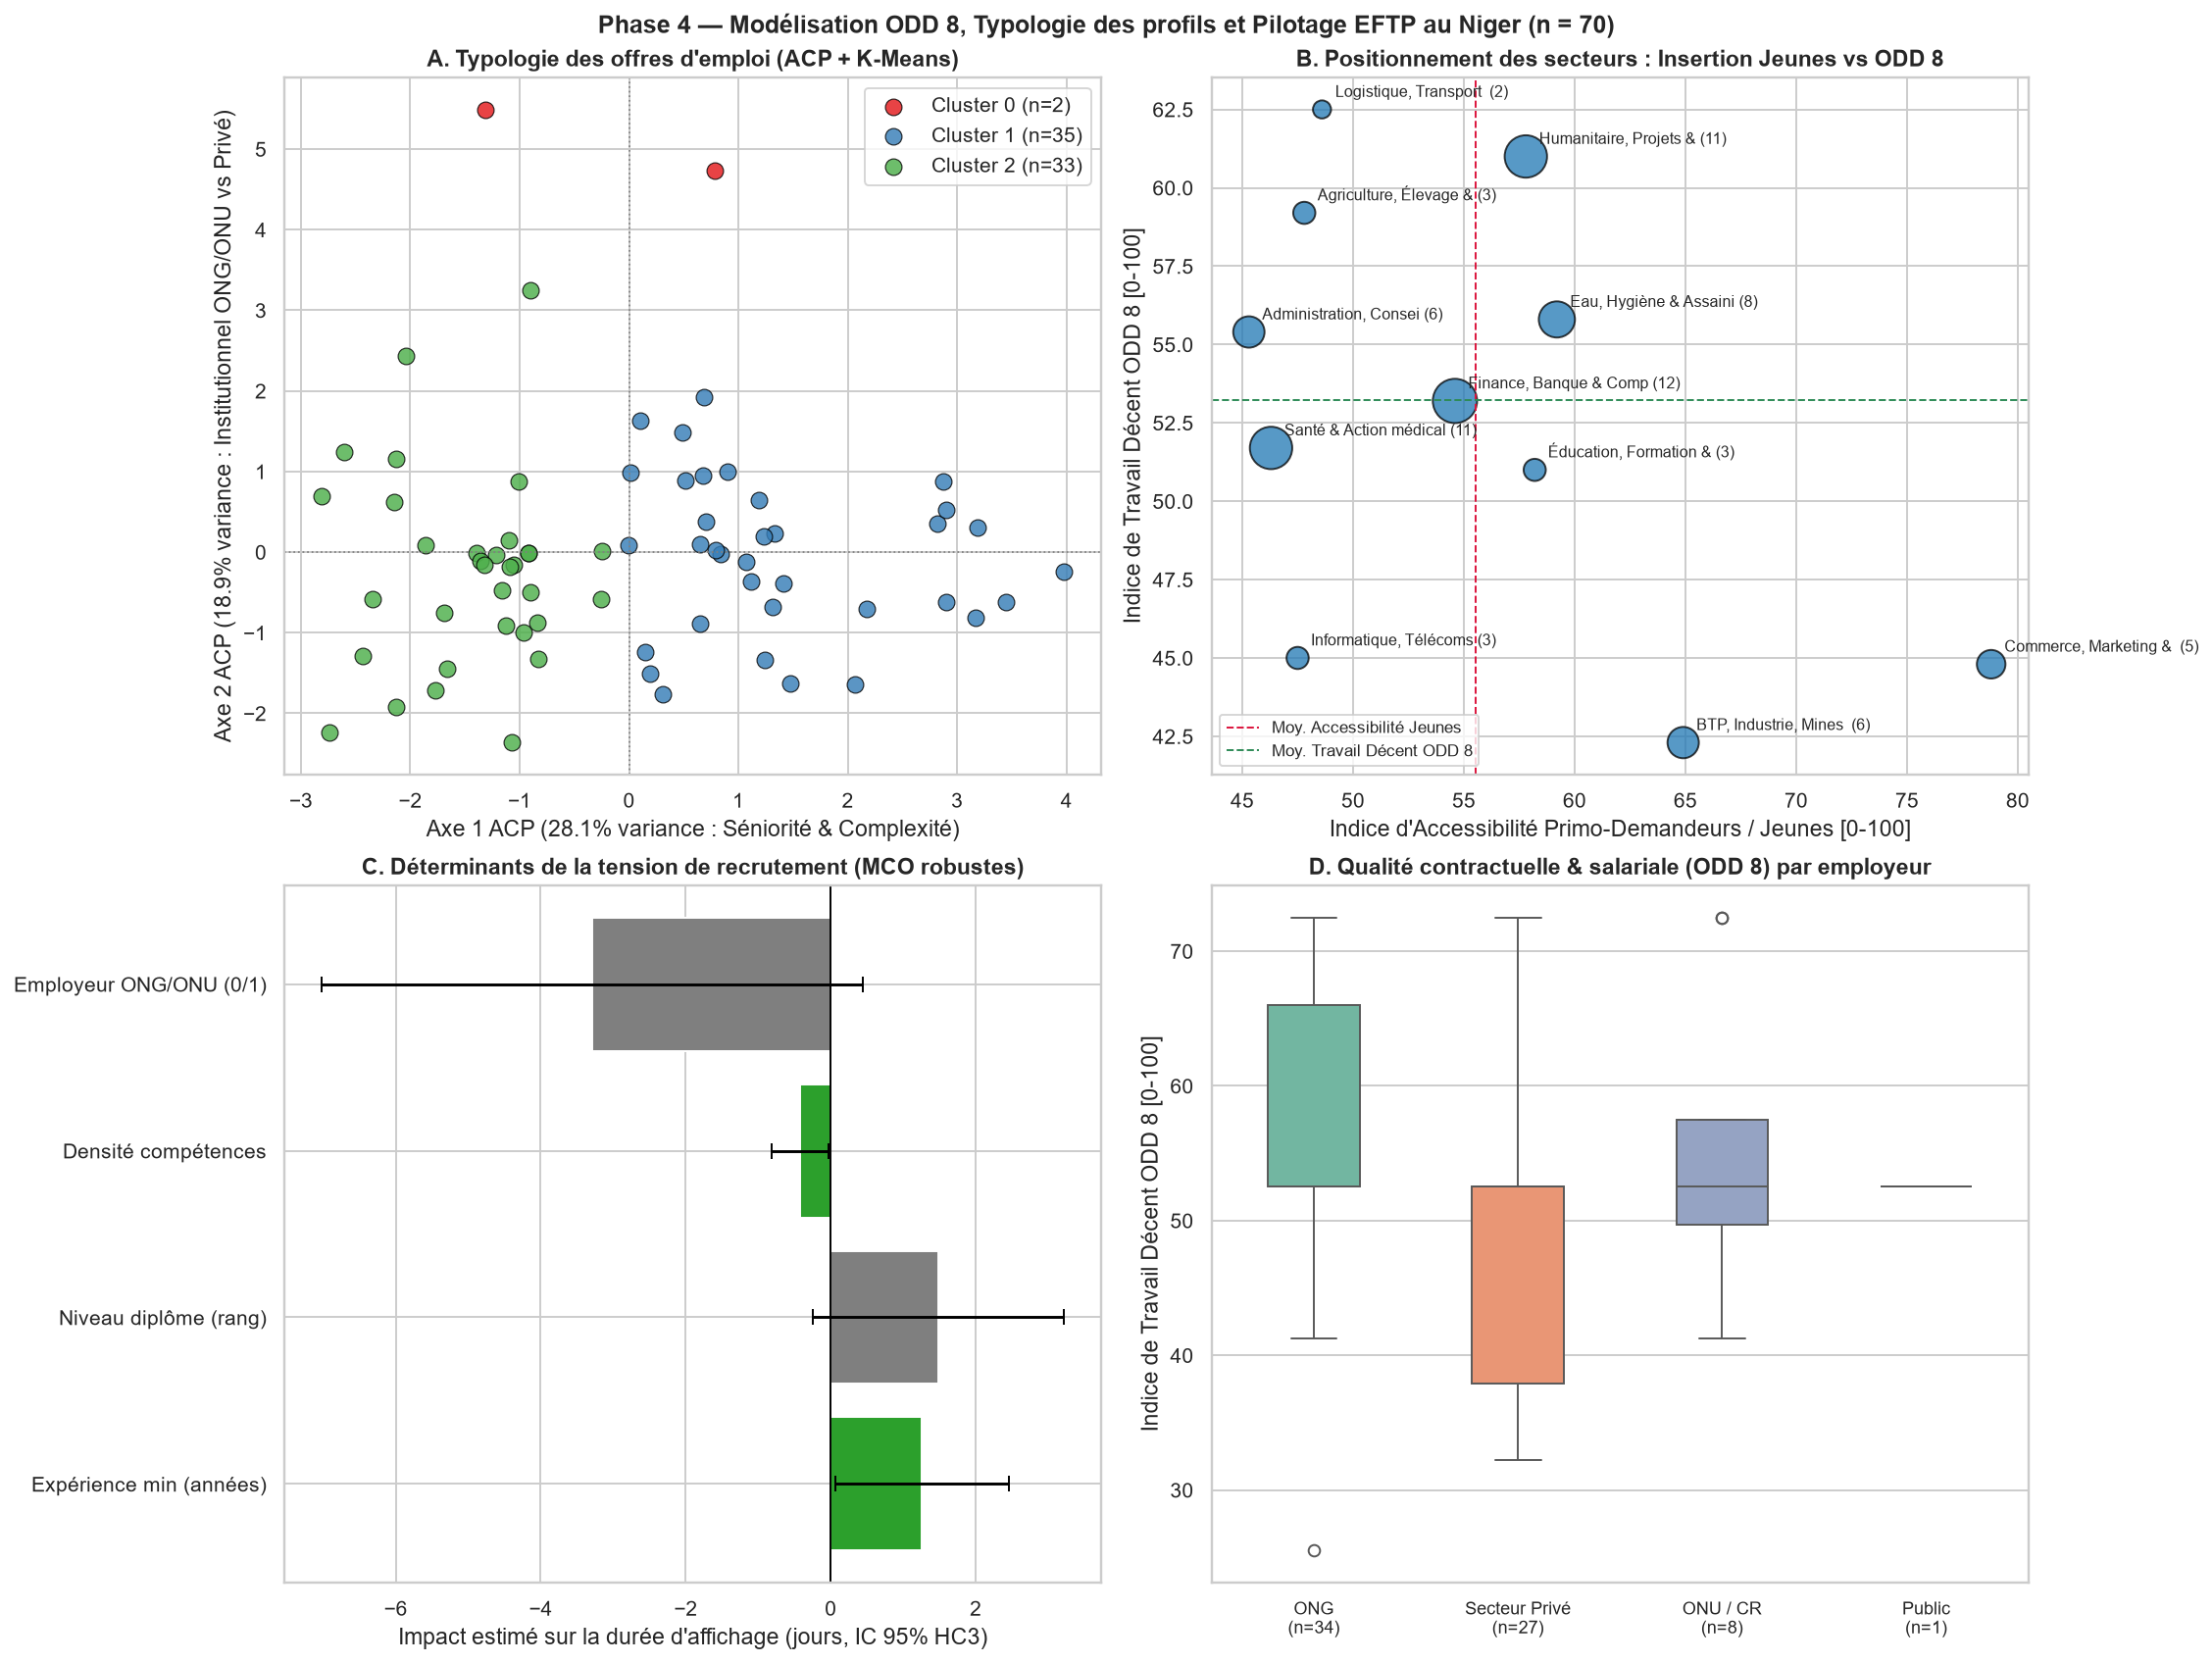

In [6]:
# ==============================================================================
# 5. VISUALISATION DE SYNTHESE PHASE 4 (2x2)
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12), constrained_layout=True)

# A. Carte factorielle ACP des profils métiers (K-Means)
ax1 = axes[0, 0]
palette_c = sns.color_palette("Set1", k_opt)
for cid in sorted(emp["cluster_id"].unique()):
    sub_c = emp[emp["cluster_id"] == cid]
    ax1.scatter(
        sub_c["pca_1"], sub_c["pca_2"],
        label=f"Cluster {cid} (n={len(sub_c)})",
        s=75, alpha=0.82, edgecolors="k", linewidth=0.6, color=palette_c[cid]
    )
ax1.axhline(0, color="grey", linestyle=":", linewidth=0.9)
ax1.axvline(0, color="grey", linestyle=":", linewidth=0.9)
ax1.set_xlabel(f"Axe 1 ACP ({var_exp[0]:.1f}% variance : Séniorité & Complexité)")
ax1.set_ylabel(f"Axe 2 ACP ({var_exp[1]:.1f}% variance : Institutionnel ONG/ONU vs Privé)")
ax1.set_title("A. Typologie des offres d'emploi (ACP + K-Means)", fontweight="bold")
ax1.legend(frameon=True)

# B. Arbitrage Accessibilité Jeunes vs Travail Décent (ODD 8) par Secteur
ax2 = axes[0, 1]
sec_plot = matrice_eftp.reset_index()
ax2.scatter(
    sec_plot["access_jeunes_moy"], sec_plot["odd8_moy"],
    s=sec_plot["nb_offres"] * 45, alpha=0.75, color="#1f77b4", edgecolors="black"
)
for _, r in sec_plot.iterrows():
    ax2.annotate(
        f"{r['secteur_canonique'][:22]} ({int(r['nb_offres'])})",
        (r["access_jeunes_moy"] + 0.6, r["odd8_moy"] + 0.4),
        fontsize=8
    )
ax2.axvline(emp["indice_accessibilite_jeunes"].mean(), color="crimson", linestyle="--", linewidth=1, label="Moy. Accessibilité Jeunes")
ax2.axhline(emp["indice_travail_decent_odd8"].mean(), color="seagreen", linestyle="--", linewidth=1, label="Moy. Travail Décent ODD 8")
ax2.set_xlabel("Indice d'Accessibilité Primo-Demandeurs / Jeunes [0-100]")
ax2.set_ylabel("Indice de Travail Décent ODD 8 [0-100]")
ax2.set_title("B. Positionnement des secteurs : Insertion Jeunes vs ODD 8", fontweight="bold")
ax2.legend(fontsize=8.5, loc="lower left")

# C. Effets marginaux (Coefficients OLS HC3) sur la durée d'affichage
ax3 = axes[1, 0]
reg_plot = res_ols[res_ols["Variable"] != "Constante"].copy()
colors_reg = ["#2ca02c" if p < 0.05 else "#7f7f7f" for p in reg_plot["p_value"]]
ax3.barh(reg_plot["Variable"], reg_plot["Coef_Beta"], xerr=1.96 * reg_plot["Erreur_Std_HC3"], color=colors_reg, capsize=4)
ax3.axvline(0, color="black", linewidth=1)
ax3.set_xlabel("Impact estimé sur la durée d'affichage (jours, IC 95% HC3)")
ax3.set_title("C. Déterminants de la tension de recrutement (MCO robustes)", fontweight="bold")

# D. Distribution de l'Indice ODD 8 par Type d'employeur
ax4 = axes[1, 1]
order_emp = ["ONG (Internationales & Nationales)", "Secteur Privé & Cabinets", "Agences ONU & Croix-Rouge", "Programmes Publics & Projets d'État"]
labels_emp = ["ONG\n(n=34)", "Secteur Privé\n(n=27)", "ONU / CR\n(n=8)", "Public\n(n=1)"]
sns.boxplot(data=emp, x="type_employeur", y="indice_travail_decent_odd8", order=order_emp, ax=ax4, palette="Set2", width=0.45)
ax4.set_xticklabels(labels_emp, fontsize=9)
ax4.set_xlabel("")
ax4.set_ylabel("Indice de Travail Décent ODD 8 [0-100]")
ax4.set_title("D. Qualité contractuelle & salariale (ODD 8) par employeur", fontweight="bold")

fig.suptitle("Phase 4 — Modélisation ODD 8, Typologie des profils et Pilotage EFTP au Niger (n = 70)", fontsize=13, fontweight="bold")
plt.savefig(BASE_DIR / "phase4_modelisation_odd8_eftp.png", bbox_inches="tight")
plt.show()


In [8]:
! pip install openpyxl --quiet
# ==============================================================================
# 6. EXPORT FINAL DES LIVRABLES (CSV ENRICHI + CLASSEUR EXCEL MULTI-ONGLETS)
# ==============================================================================
emp.to_csv(BASE_DIR / "offres_niger_final_odd8.csv", index=False)

excel_path = BASE_DIR / "synthese_marche_emploi_niger_odd8.xlsx"
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    emp.drop(columns=["savoirs_list", "savoir_faire_list", "outils_list", "savoir_etre_list", "texte_nlp"]).to_excel(
        writer, sheet_name="Base_Emploi_Enrichie", index=False
    )
    matrice_eftp.reset_index().to_excel(writer, sheet_name="Matrice_Curricula_EFTP", index=False)
    profil_clusters.reset_index().to_excel(writer, sheet_name="Typologie_Clusters", index=False)
    res_ols.to_excel(writer, sheet_name="Regression_Tension_OLS", index=False)
    matrice_geo.reset_index().to_excel(writer, sheet_name="Repartition_Geographique", index=False)

print(f"\nPipeline complet terminé ! Livrables générés dans : {BASE_DIR}")
print("  1. phase4_modelisation_odd8_eftp.png")
print("  2. offres_niger_final_odd8.csv")
print("  3. synthese_marche_emploi_niger_odd8.xlsx (5 onglets analytiques)")


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



Pipeline complet terminé ! Livrables générés dans : C:\Projet Niger Labor Market\niger_jobs_scraper\data\cleaned
  1. phase4_modelisation_odd8_eftp.png
  2. offres_niger_final_odd8.csv
  3. synthese_marche_emploi_niger_odd8.xlsx (5 onglets analytiques)
